<a href="https://colab.research.google.com/github/krishnanpatil1212/ML-project-/blob/main/project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================================
# PROJECT 59
# CONSUMER ELECTRONICS SMARTPHONE PRICE RANGE TIER CATEGORIZATION
# ============================================================

print("=" * 70)
print("CONSUMER ELECTRONICS SMARTPHONE PRICE RANGE TIER CATEGORIZATION")
print("=" * 70)

print("\nApplication Domain:")
print("Consumer Electronics & Product Pricing Strategy")

print("\nAlgorithms:")
print("1. Decision Tree Classifier")
print("2. Gaussian Naive Bayes")
print("3. Linear Support Vector Machine")
print("4. RBF Support Vector Machine")
print("5. K-Nearest Neighbors")

print("\nTarget Classes:")
print("0 = Low Cost")
print("1 = Medium")
print("2 = High")
print("3 = Very High / Flagship Premium")

print("\nRandom State: 42")


CONSUMER ELECTRONICS SMARTPHONE PRICE RANGE TIER CATEGORIZATION

Application Domain:
Consumer Electronics & Product Pricing Strategy

Algorithms:
1. Decision Tree Classifier
2. Gaussian Naive Bayes
3. Linear Support Vector Machine
4. RBF Support Vector Machine
5. K-Nearest Neighbors

Target Classes:
0 = Low Cost
1 = Medium
2 = High
3 = Very High / Flagship Premium

Random State: 42


In [ ]:
# ============================================================
# PROBLEM STATEMENT
# ============================================================

problem_statement = """
The objective of this project is to classify smartphones into four
price tiers using their hardware and connectivity specifications.

The four target categories are:
0 - Low Cost
1 - Medium
2 - High
3 - Very High / Flagship Premium

The dataset contains 2,000 smartphones and 20 hardware-related
features including RAM, battery power, processor clock speed,
internal memory, camera specifications, pixel dimensions,
connectivity features, and screen dimensions.

Five machine-learning algorithms are compared:
Decision Tree, Gaussian Naive Bayes, Linear SVM, RBF SVM,
and K-Nearest Neighbors.

The project also investigates feature importance, model
performance, confusion matrices, permutation importance,
and two-dimensional decision boundaries using RAM and
battery power.
"""

print(problem_statement)



The objective of this project is to classify smartphones into four
price tiers using their hardware and connectivity specifications.

The four target categories are:
0 - Low Cost
1 - Medium
2 - High
3 - Very High / Flagship Premium

The dataset contains 2,000 smartphones and 20 hardware-related
features including RAM, battery power, processor clock speed,
internal memory, camera specifications, pixel dimensions,
connectivity features, and screen dimensions.

Five machine-learning algorithms are compared:
Decision Tree, Gaussian Naive Bayes, Linear SVM, RBF SVM,
and K-Nearest Neighbors.

The project also investigates feature importance, model
performance, confusion matrices, permutation importance,
and two-dimensional decision boundaries using RAM and
battery power.



In [ ]:
# ============================================================
# IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold,
    cross_val_score
)

from sklearn.preprocessing import StandardScaler

from sklearn.tree import DecisionTreeClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.svm import SVC

from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from sklearn.inspection import permutation_importance

import warnings
warnings.filterwarnings("ignore")

# Reproducibility
RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)

# Plot style
sns.set_style("whitegrid")

print("All libraries imported successfully.")


All libraries imported successfully.


In [ ]:
# ============================================================
# LOAD DATASET
# ============================================================

import os
import zipfile
from google.colab import files

# Check if train.csv or archive.zip is already present
if not os.path.exists("train.csv") and not os.path.exists("archive.zip"):
    print("Please upload 'train.csv' or the 'archive.zip' file:")
    uploaded = files.upload()

# If archive.zip was uploaded, extract it to get train.csv
if os.path.exists("archive.zip") and not os.path.exists("train.csv"):
    print("Extracting archive.zip...")
    with zipfile.ZipFile("archive.zip", "r") as zip_ref:
        zip_ref.extractall(".")

# Load dataset
df = pd.read_csv("train.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (2000, 21)


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


In [ ]:
# ============================================================
# DATASET EXPLORATION
# ============================================================

print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

print("\nLast 5 Rows:")
display(df.tail())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe().T)


Dataset Shape:
(2000, 21)

Column Names:
['battery_power', 'blue', 'clock_speed', 'dual_sim', 'fc', 'four_g', 'int_memory', 'm_dep', 'mobile_wt', 'n_cores', 'pc', 'px_height', 'px_width', 'ram', 'sc_h', 'sc_w', 'talk_time', 'three_g', 'touch_screen', 'wifi', 'price_range']

First 5 Rows:


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1



Last 5 Rows:


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
1995,794,1,0.5,1,0,1,2,0.8,106,6,...,1222,1890,668,13,4,19,1,1,0,0
1996,1965,1,2.6,1,0,0,39,0.2,187,4,...,915,1965,2032,11,10,16,1,1,1,2
1997,1911,0,0.9,1,1,1,36,0.7,108,8,...,868,1632,3057,9,1,5,1,1,0,3
1998,1512,0,0.9,0,4,1,46,0.1,145,5,...,336,670,869,18,10,19,1,1,1,0
1999,510,1,2.0,1,5,1,45,0.9,168,6,...,483,754,3919,19,4,2,1,1,1,3



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  2000 non-null   int64  
 1   blue           2000 non-null   int64  
 2   clock_speed    2000 non-null   float64
 3   dual_sim       2000 non-null   int64  
 4   fc             2000 non-null   int64  
 5   four_g         2000 non-null   int64  
 6   int_memory     2000 non-null   int64  
 7   m_dep          2000 non-null   float64
 8   mobile_wt      2000 non-null   int64  
 9   n_cores        2000 non-null   int64  
 10  pc             2000 non-null   int64  
 11  px_height      2000 non-null   int64  
 12  px_width       2000 non-null   int64  
 13  ram            2000 non-null   int64  
 14  sc_h           2000 non-null   int64  
 15  sc_w           2000 non-null   int64  
 16  talk_time      2000 non-null   int64  
 17  three_g        2000 non-null  

,count,mean,std,min,25%,50%,75%,max
battery_power,2000.0,1238.51850,439.418206,501.0,851.75,1226.0,1615.25,1998.0
blue,2000.0,0.49500,0.500100,0.0,0.00,0.0,1.00,1.0
clock_speed,2000.0,1.52225,0.816004,0.5,0.70,1.5,2.20,3.0
dual_sim,2000.0,0.50950,0.500035,0.0,0.00,1.0,1.00,1.0
fc,2000.0,4.30950,4.341444,0.0,1.00,3.0,7.00,19.0
four_g,2000.0,0.52150,0.499662,0.0,0.00,1.0,1.00,1.0
int_memory,2000.0,32.04650,18.145715,2.0,16.00,32.0,48.00,64.0
m_dep,2000.0,0.50175,0.288416,0.1,0.20,0.5,0.80,1.0
mobile_wt,2000.0,140.24900,35.399655,80.0,109.00,141.0,170.00,200.0
n_cores,2000.0,4.52050,2.287837,1.0,3.00,4.0,7.00,8.0


In [ ]:
# ============================================================
# DATA QUALITY CHECKING
# ============================================================

# Missing values
missing_values = df.isnull().sum()

missing_table = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (
        missing_values / len(df) * 100
    ).round(2)
})

print("Missing Value Analysis:")
display(missing_table)

# Total missing values
print(
    "\nTotal Missing Values:",
    df.isnull().sum().sum()
)

# Duplicate rows
duplicate_count = df.duplicated().sum()

print(
    "Number of Duplicate Rows:",
    duplicate_count
)

# Data types
print("\nData Types:")
display(
    pd.DataFrame({
        "Feature": df.columns,
        "Data Type": df.dtypes.astype(str).values
    })
)


Missing Value Analysis:


,Missing Values,Missing Percentage
battery_power,0,0.0
blue,0,0.0
clock_speed,0,0.0
dual_sim,0,0.0
fc,0,0.0
four_g,0,0.0
int_memory,0,0.0
m_dep,0,0.0
mobile_wt,0,0.0
n_cores,0,0.0



Total Missing Values: 0
Number of Duplicate Rows: 0

Data Types:


,Feature,Data Type
0,battery_power,int64
1,blue,int64
2,clock_speed,float64
3,dual_sim,int64
4,fc,int64
5,four_g,int64
6,int_memory,int64
7,m_dep,float64
8,mobile_wt,int64
9,n_cores,int64


Price Tier Distribution:


,count
price_range,
0,500
1,500
2,500
3,500



Percentage Distribution:


,proportion
price_range,
0,25.0
1,25.0
2,25.0
3,25.0


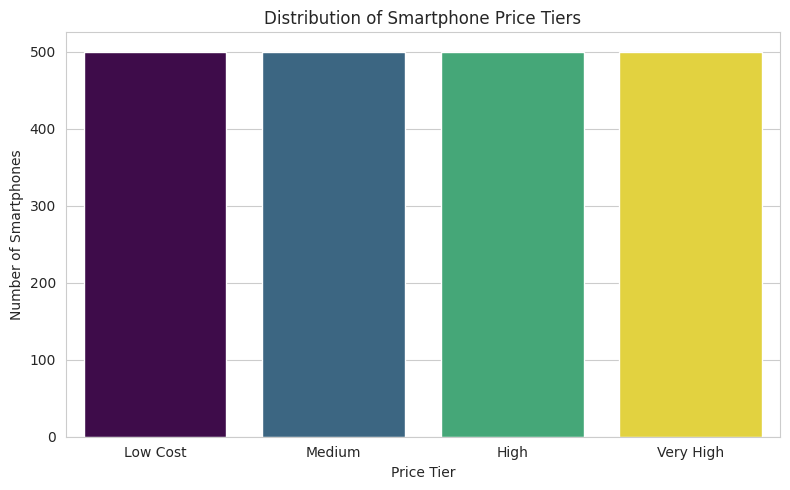

In [ ]:
# ============================================================
# TARGET DISTRIBUTION
# ============================================================

price_counts = (
    df["price_range"]
    .value_counts()
    .sort_index()
)

print("Price Tier Distribution:")
display(price_counts)

# Percentage distribution
price_percent = (
    df["price_range"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

print("\nPercentage Distribution:")
display(price_percent)

# Visualization
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="price_range",
    hue="price_range",
    palette="viridis",
    legend=False
)

plt.title("Distribution of Smartphone Price Tiers")
plt.xlabel("Price Tier")
plt.ylabel("Number of Smartphones")

plt.xticks(
    [0, 1, 2, 3],
    ["Low Cost", "Medium", "High", "Very High"]
)

plt.tight_layout()
plt.show()


Price Tier Distribution:


,count
price_range,
0,500
1,500
2,500
3,500



Percentage Distribution:


,proportion
price_range,
0,25.0
1,25.0
2,25.0
3,25.0


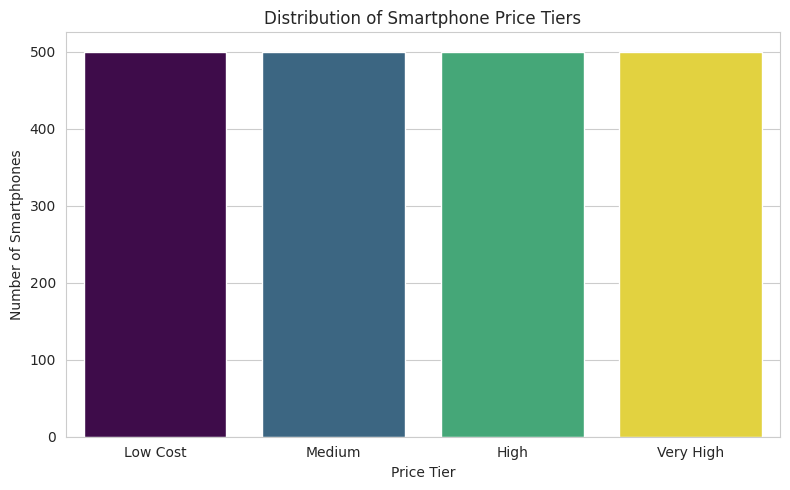

In [ ]:
# ============================================================
# TARGET DISTRIBUTION
# ============================================================

price_counts = (
    df["price_range"]
    .value_counts()
    .sort_index()
)

print("Price Tier Distribution:")
display(price_counts)

# Percentage distribution
price_percent = (
    df["price_range"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

print("\nPercentage Distribution:")
display(price_percent)

# Visualization
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="price_range",
    hue="price_range",
    palette="viridis",
    legend=False
)

plt.title("Distribution of Smartphone Price Tiers")
plt.xlabel("Price Tier")
plt.ylabel("Number of Smartphones")

plt.xticks(
    [0, 1, 2, 3],
    ["Low Cost", "Medium", "High", "Very High"]
)

plt.tight_layout()
plt.show()


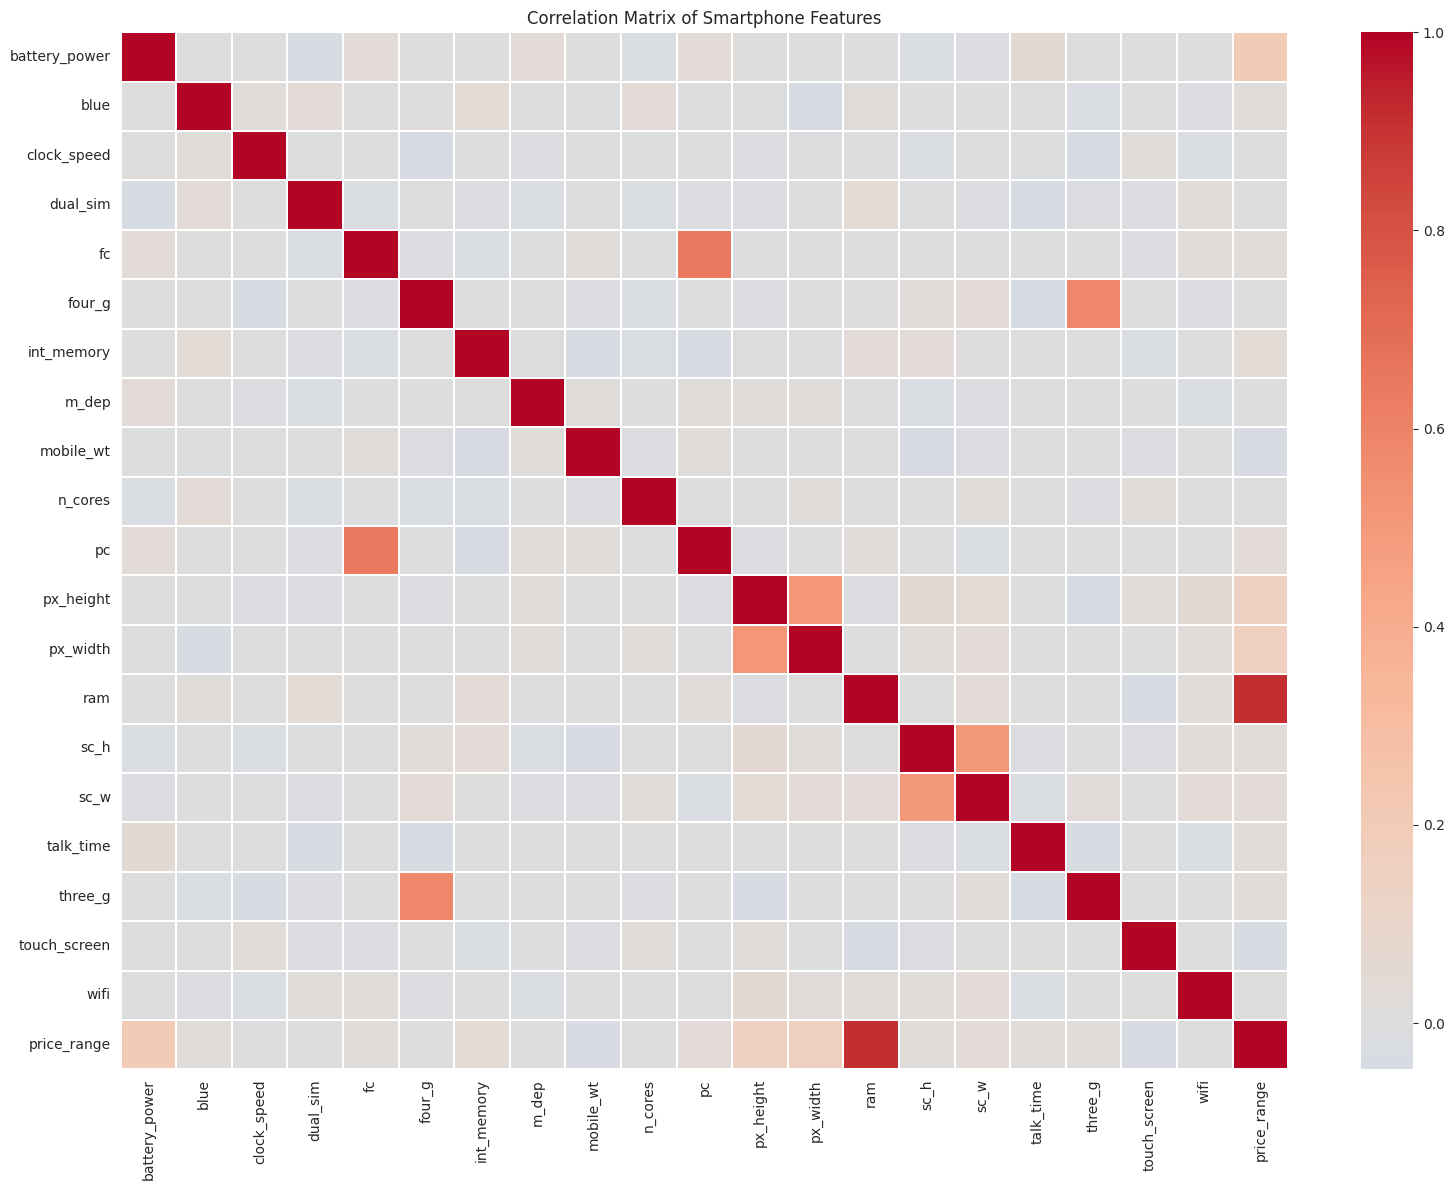

Correlation of Features with Price Range:


,Correlation
ram,0.917046
battery_power,0.200723
px_width,0.165818
px_height,0.148858
int_memory,0.044435
sc_w,0.038711
pc,0.033599
three_g,0.023611
sc_h,0.022986
fc,0.021998


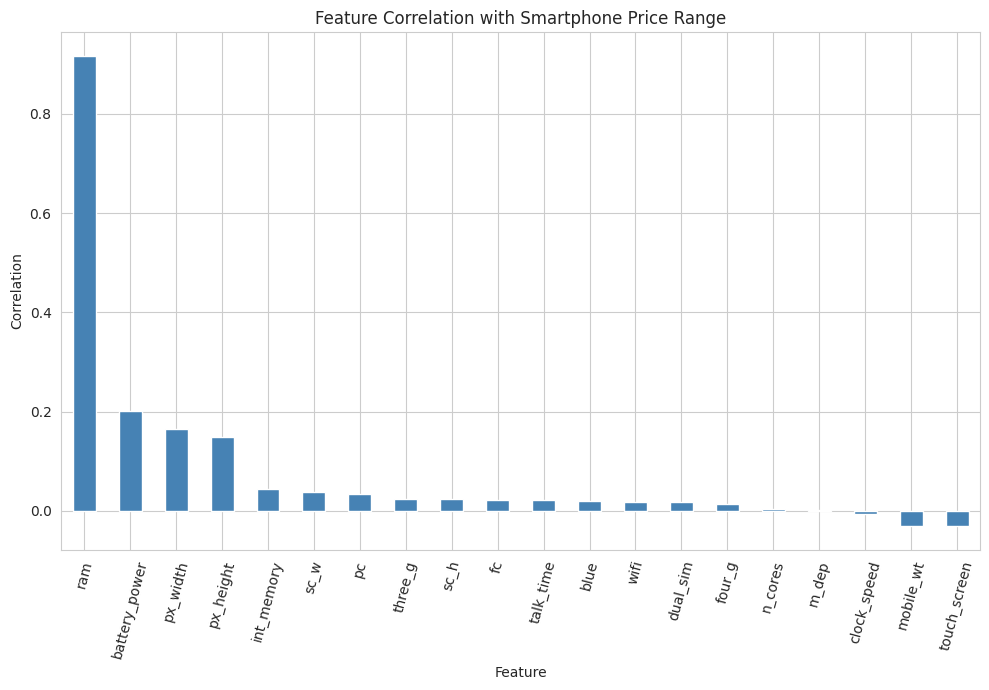

In [ ]:
# ============================================================
# CORRELATION ANALYSIS
# ============================================================

correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.3
)

plt.title(
    "Correlation Matrix of Smartphone Features"
)

plt.tight_layout()
plt.show()

# Correlation with target
price_correlations = (
    correlation_matrix["price_range"]
    .drop("price_range")
    .sort_values(ascending=False)
)

print("Correlation of Features with Price Range:")
display(price_correlations.to_frame("Correlation"))

# Plot target correlations
plt.figure(figsize=(10, 7))

price_correlations.plot(
    kind="bar",
    color="steelblue"
)

plt.title(
    "Feature Correlation with Smartphone Price Range"
)

plt.xlabel("Feature")
plt.ylabel("Correlation")

plt.xticks(rotation=75)

plt.tight_layout()
plt.show()


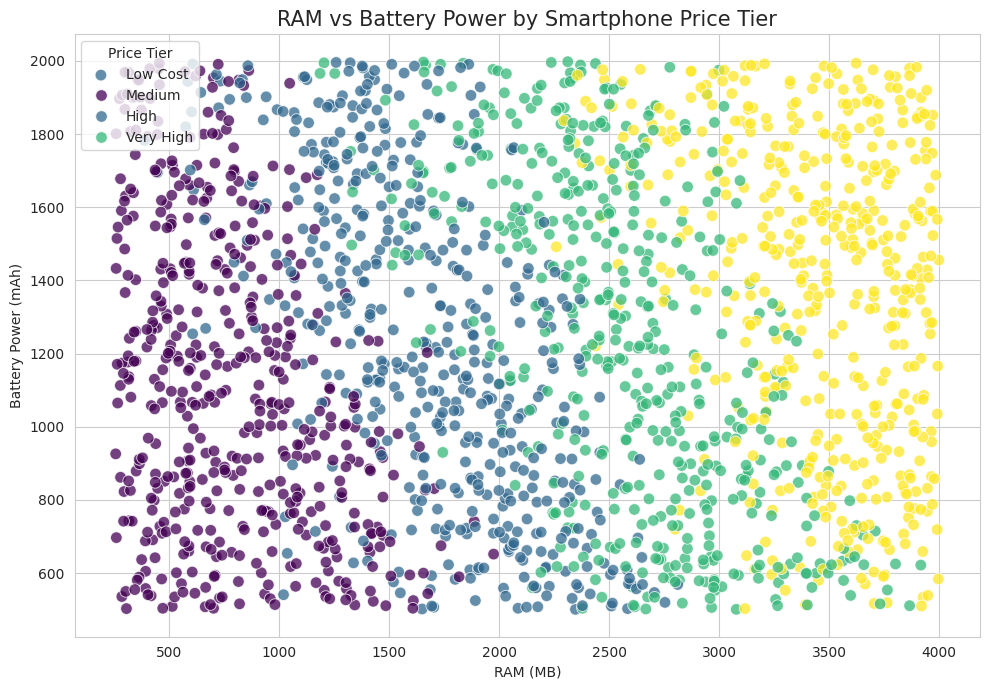

In [ ]:
# ============================================================
# REQUIRED SCATTER PLOT
# RAM VS BATTERY POWER
# ============================================================

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df,
    x="ram",
    y="battery_power",
    hue="price_range",
    palette="viridis",
    alpha=0.75,
    s=70
)

plt.title(
    "RAM vs Battery Power by Smartphone Price Tier",
    fontsize=15
)

plt.xlabel("RAM (MB)")
plt.ylabel("Battery Power (mAh)")

plt.legend(
    title="Price Tier",
    labels=[
        "Low Cost",
        "Medium",
        "High",
        "Very High"
    ]
)

plt.tight_layout()
plt.show()


In [ ]:
# ============================================================
# FEATURE / TARGET SEPARATION
# ============================================================

# X = input features
# y = target variable

X = df.drop(
    "price_range",
    axis=1
)

y = df["price_range"]

print("Feature Matrix Shape:")
print(X.shape)

print("\nTarget Shape:")
print(y.shape)

print("\nInput Features:")
print(X.columns.tolist())

print("\nTarget Classes:")
print(sorted(y.unique()))


Feature Matrix Shape:
(2000, 20)

Target Shape:
(2000,)

Input Features:
['battery_power', 'blue', 'clock_speed', 'dual_sim', 'fc', 'four_g', 'int_memory', 'm_dep', 'mobile_wt', 'n_cores', 'pc', 'px_height', 'px_width', 'ram', 'sc_h', 'sc_w', 'talk_time', 'three_g', 'touch_screen', 'wifi']

Target Classes:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3)]


In [ ]:
# ============================================================
# TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training Set Shape:")
print(X_train.shape)

print("\nTesting Set Shape:")
print(X_test.shape)

print("\nTraining Class Distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting Class Distribution:")
print(y_test.value_counts().sort_index())


Training Set Shape:
(1600, 20)

Testing Set Shape:
(400, 20)

Training Class Distribution:
price_range
0    400
1    400
2    400
3    400
Name: count, dtype: int64

Testing Class Distribution:
price_range
0    100
1    100
2    100
3    100
Name: count, dtype: int64


In [ ]:
# ============================================================
# FEATURE STANDARDIZATION
# ============================================================

scaler = StandardScaler()

# Fit ONLY on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform test data using the training scaler
X_test_scaled = scaler.transform(X_test)

# Convert back to DataFrames for readability
X_train_scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled_df = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns,
    index=X_test.index
)

print("Standardization completed.")

print("\nFirst 5 standardized training records:")
display(X_train_scaled_df.head())

print("\nTraining means after scaling:")
print(X_train_scaled_df.mean().round(4))

print("\nTraining standard deviations after scaling:")
print(X_train_scaled_df.std().round(4))


Standardization completed.

First 5 standardized training records:


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,pc,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi
469,1.389193,1.011314,-1.259189,0.986343,1.309253,-1.036932,1.584829,-0.704590,-1.250335,-1.551637,0.350239,-0.798849,-1.285642,-0.363024,-0.781290,-0.177627,-0.896645,-1.788708,-1.008789,-1.025320
565,0.078406,1.011314,-1.259189,-1.013846,1.770460,-1.036932,-0.003457,-1.396849,-0.768374,1.073159,0.844549,1.582302,1.637675,-1.547896,0.647082,1.875207,0.560944,-1.788708,-1.008789,0.975305
396,-1.024573,-0.988813,1.187471,0.986343,-0.074370,0.964384,1.365755,1.372187,-1.392089,1.510625,0.350239,-1.361502,-0.199305,1.698985,-0.067104,0.506651,-0.896645,0.559063,0.991288,0.975305
452,0.386692,-0.988813,-1.259189,0.986343,-0.535577,0.964384,0.106080,1.026057,-1.193634,-0.676705,-0.803150,0.832847,0.278589,1.649232,-0.781290,0.506651,-1.625440,0.559063,-1.008789,0.975305
325,-0.723138,-0.988813,0.698139,0.986343,0.156234,-1.036932,-0.386837,-0.358460,-0.711673,1.073159,0.679779,-0.985650,-0.392794,-1.234632,-0.543228,0.278558,-1.078844,-1.788708,0.991288,0.975305



Training means after scaling:
battery_power   -0.0
blue            -0.0
clock_speed     -0.0
dual_sim         0.0
fc               0.0
four_g           0.0
int_memory       0.0
m_dep           -0.0
mobile_wt        0.0
n_cores         -0.0
pc              -0.0
px_height        0.0
px_width         0.0
ram             -0.0
sc_h             0.0
sc_w             0.0
talk_time       -0.0
three_g          0.0
touch_screen    -0.0
wifi             0.0
dtype: float64

Training standard deviations after scaling:
battery_power    1.0003
blue             1.0003
clock_speed      1.0003
dual_sim         1.0003
fc               1.0003
four_g           1.0003
int_memory       1.0003
m_dep            1.0003
mobile_wt        1.0003
n_cores          1.0003
pc               1.0003
px_height        1.0003
px_width         1.0003
ram              1.0003
sc_h             1.0003
sc_w             1.0003
talk_time        1.0003
three_g          1.0003
touch_screen     1.0003
wifi             1.0003
dtype: fl

In [ ]:
# ============================================================
# DECISION TREE CLASSIFIER
# ============================================================

dt_model = DecisionTreeClassifier(
    random_state=RANDOM_STATE
)

# Decision Trees do not require feature scaling
dt_model.fit(
    X_train,
    y_train
)

dt_pred = dt_model.predict(
    X_test
)

dt_accuracy = accuracy_score(
    y_test,
    dt_pred
)

print("Decision Tree Accuracy:")
print(f"{dt_accuracy:.4f}")

print("\nDecision Tree Classification Report:")

print(
    classification_report(
        y_test,
        dt_pred,
        target_names=[
            "Low Cost",
            "Medium",
            "High",
            "Very High"
        ]
    )
)


Decision Tree Accuracy:
0.8300

Decision Tree Classification Report:
              precision    recall  f1-score   support

    Low Cost       0.88      0.92      0.90       100
      Medium       0.78      0.74      0.76       100
        High       0.75      0.80      0.77       100
   Very High       0.92      0.86      0.89       100

    accuracy                           0.83       400
   macro avg       0.83      0.83      0.83       400
weighted avg       0.83      0.83      0.83       400



In [ ]:
# ============================================================
# GAUSSIAN NAIVE BAYES
# ============================================================

nb_model = GaussianNB()

# Use standardized features
nb_model.fit(
    X_train_scaled,
    y_train
)

nb_pred = nb_model.predict(
    X_test_scaled
)

nb_accuracy = accuracy_score(
    y_test,
    nb_pred
)

print("Gaussian Naive Bayes Accuracy:")
print(f"{nb_accuracy:.4f}")

print("\nGaussian Naive Bayes Classification Report:")

print(
    classification_report(
        y_test,
        nb_pred,
        target_names=[
            "Low Cost",
            "Medium",
            "High",
            "Very High"
        ]
    )
)


Gaussian Naive Bayes Accuracy:
0.8100

Gaussian Naive Bayes Classification Report:
              precision    recall  f1-score   support

    Low Cost       0.93      0.90      0.91       100
      Medium       0.71      0.69      0.70       100
        High       0.70      0.73      0.71       100
   Very High       0.91      0.92      0.92       100

    accuracy                           0.81       400
   macro avg       0.81      0.81      0.81       400
weighted avg       0.81      0.81      0.81       400



In [ ]:
# ============================================================
# LINEAR SUPPORT VECTOR MACHINE
# ============================================================

linear_svm = SVC(
    kernel="linear",
    random_state=RANDOM_STATE
)

linear_svm.fit(
    X_train_scaled,
    y_train
)

linear_pred = linear_svm.predict(
    X_test_scaled
)

linear_accuracy = accuracy_score(
    y_test,
    linear_pred
)

print("Linear SVM Accuracy:")
print(f"{linear_accuracy:.4f}")

print("\nLinear SVM Classification Report:")

print(
    classification_report(
        y_test,
        linear_pred,
        target_names=[
            "Low Cost",
            "Medium",
            "High",
            "Very High"
        ]
    )
)


Linear SVM Accuracy:
0.9625

Linear SVM Classification Report:
              precision    recall  f1-score   support

    Low Cost       0.99      0.96      0.97       100
      Medium       0.95      0.95      0.95       100
        High       0.95      0.95      0.95       100
   Very High       0.96      0.99      0.98       100

    accuracy                           0.96       400
   macro avg       0.96      0.96      0.96       400
weighted avg       0.96      0.96      0.96       400



In [ ]:
# ============================================================
# RBF SUPPORT VECTOR MACHINE
# ============================================================

rbf_svm = SVC(
    kernel="rbf",
    random_state=RANDOM_STATE
)

rbf_svm.fit(
    X_train_scaled,
    y_train
)

rbf_pred = rbf_svm.predict(
    X_test_scaled
)

rbf_accuracy = accuracy_score(
    y_test,
    rbf_pred
)

print("RBF SVM Accuracy:")
print(f"{rbf_accuracy:.4f}")

print("\nRBF SVM Classification Report:")

print(
    classification_report(
        y_test,
        rbf_pred,
        target_names=[
            "Low Cost",
            "Medium",
            "High",
            "Very High"
        ]
    )
)


RBF SVM Accuracy:
0.8950

RBF SVM Classification Report:
              precision    recall  f1-score   support

    Low Cost       0.96      0.94      0.95       100
      Medium       0.87      0.87      0.87       100
        High       0.82      0.87      0.84       100
   Very High       0.94      0.90      0.92       100

    accuracy                           0.90       400
   macro avg       0.90      0.90      0.90       400
weighted avg       0.90      0.90      0.90       400



In [ ]:
# ============================================================
# K-NEAREST NEIGHBORS
# ============================================================

knn_model = KNeighborsClassifier(
    n_neighbors=5
)

knn_model.fit(
    X_train_scaled,
    y_train
)

knn_pred = knn_model.predict(
    X_test_scaled
)

knn_accuracy = accuracy_score(
    y_test,
    knn_pred
)

print("KNN Accuracy:")
print(f"{knn_accuracy:.4f}")

print("\nKNN Classification Report:")

print(
    classification_report(
        y_test,
        knn_pred,
        target_names=[
            "Low Cost",
            "Medium",
            "High",
            "Very High"
        ]
    )
)


KNN Accuracy:
0.5000

KNN Classification Report:
              precision    recall  f1-score   support

    Low Cost       0.65      0.70      0.67       100
      Medium       0.33      0.38      0.35       100
        High       0.39      0.41      0.40       100
   Very High       0.72      0.51      0.60       100

    accuracy                           0.50       400
   macro avg       0.52      0.50      0.51       400
weighted avg       0.52      0.50      0.51       400



In [ ]:
# ============================================================
# GRIDSEARCHCV - HYPERPARAMETER TUNING
# ============================================================

cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# ------------------------------------------------------------
# 1. DECISION TREE
# ------------------------------------------------------------

dt_param_grid = {
    "max_depth": [3, 5, 7, 9, 11, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

dt_grid = GridSearchCV(
    DecisionTreeClassifier(
        random_state=RANDOM_STATE
    ),
    param_grid=dt_param_grid,
    cv=cv_strategy,
    scoring="accuracy",
    n_jobs=-1
)

dt_grid.fit(
    X_train,
    y_train
)

# ------------------------------------------------------------
# 2. LINEAR SVM
# ------------------------------------------------------------

linear_svm_grid = GridSearchCV(
    SVC(kernel="linear"),
    param_grid={
        "C": [0.01, 0.1, 1, 10, 100]
    },
    cv=cv_strategy,
    scoring="accuracy",
    n_jobs=-1
)

linear_svm_grid.fit(
    X_train_scaled,
    y_train
)

# ------------------------------------------------------------
# 3. RBF SVM
# ------------------------------------------------------------

rbf_svm_grid = GridSearchCV(
    SVC(kernel="rbf"),
    param_grid={
        "C": [0.1, 1, 10, 100],
        "gamma": ["scale", 0.001, 0.01, 0.1, 1]
    },
    cv=cv_strategy,
    scoring="accuracy",
    n_jobs=-1
)

rbf_svm_grid.fit(
    X_train_scaled,
    y_train
)

# ------------------------------------------------------------
# 4. KNN
# ------------------------------------------------------------

knn_grid = GridSearchCV(
    KNeighborsClassifier(),
    param_grid={
        "n_neighbors": [3, 5, 7, 9, 11, 15],
        "weights": ["uniform", "distance"],
        "metric": ["euclidean", "manhattan"]
    },
    cv=cv_strategy,
    scoring="accuracy",
    n_jobs=-1
)

knn_grid.fit(
    X_train_scaled,
    y_train
)

# ------------------------------------------------------------
# PRINT RESULTS
# ------------------------------------------------------------

print("=" * 70)
print("BEST HYPERPARAMETERS")
print("=" * 70)

print("\nDecision Tree:")
print(dt_grid.best_params_)
print("Best CV Accuracy:", round(dt_grid.best_score_, 4))

print("\nLinear SVM:")
print(linear_svm_grid.best_params_)
print("Best CV Accuracy:", round(linear_svm_grid.best_score_, 4))

print("\nRBF SVM:")
print(rbf_svm_grid.best_params_)
print("Best CV Accuracy:", round(rbf_svm_grid.best_score_, 4))

print("\nKNN:")
print(knn_grid.best_params_)
print("Best CV Accuracy:", round(knn_grid.best_score_, 4))


BEST HYPERPARAMETERS

Decision Tree:
{'max_depth': 9, 'min_samples_leaf': 4, 'min_samples_split': 2}
Best CV Accuracy: 0.8375

Linear SVM:
{'C': 10}
Best CV Accuracy: 0.9638

RBF SVM:
{'C': 100, 'gamma': 0.001}
Best CV Accuracy: 0.9362

KNN:
{'metric': 'manhattan', 'n_neighbors': 15, 'weights': 'distance'}
Best CV Accuracy: 0.6069


In [ ]:
# ============================================================
# MODEL EVALUATION
# ============================================================

# Get optimized models
best_dt = dt_grid.best_estimator_
best_linear_svm = linear_svm_grid.best_estimator_
best_rbf_svm = rbf_svm_grid.best_estimator_
best_knn = knn_grid.best_estimator_

# Predictions from optimized models
dt_pred_final = best_dt.predict(X_test)

nb_pred_final = nb_model.predict(X_test_scaled)

linear_pred_final = best_linear_svm.predict(
    X_test_scaled
)

rbf_pred_final = best_rbf_svm.predict(
    X_test_scaled
)

knn_pred_final = best_knn.predict(
    X_test_scaled
)

# Dictionary of predictions
predictions = {
    "Decision Tree": dt_pred_final,
    "Gaussian Naive Bayes": nb_pred_final,
    "Linear SVM": linear_pred_final,
    "RBF SVM": rbf_pred_final,
    "KNN": knn_pred_final
}

# Evaluate every model
evaluation_results = []

for model_name, pred in predictions.items():

    evaluation_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(
            y_test, pred
        ),
        "Precision": precision_score(
            y_test,
            pred,
            average="weighted"
        ),
        "Recall": recall_score(
            y_test,
            pred,
            average="weighted"
        ),
        "F1 Score": f1_score(
            y_test,
            pred,
            average="weighted"
        )
    })

results_df = pd.DataFrame(
    evaluation_results
)

results_df = results_df.sort_values(
    "Accuracy",
    ascending=False
).reset_index(drop=True)

print("FINAL MODEL EVALUATION")
display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}"
    })
)


FINAL MODEL EVALUATION


,Model,Accuracy,Precision,Recall,F1 Score
0,Linear SVM,0.9750,0.9750,0.9750,0.9750
1,RBF SVM,0.9675,0.9676,0.9675,0.9675
2,Decision Tree,0.8600,0.8615,0.8600,0.8597
3,Gaussian Naive Bayes,0.8100,0.8113,0.8100,0.8105
4,KNN,0.6425,0.6399,0.6425,0.6408


Best Performing Model:
Linear SVM

Confusion Matrix:
[[98  2  0  0]
 [ 1 96  3  0]
 [ 0  1 97  2]
 [ 0  0  1 99]]


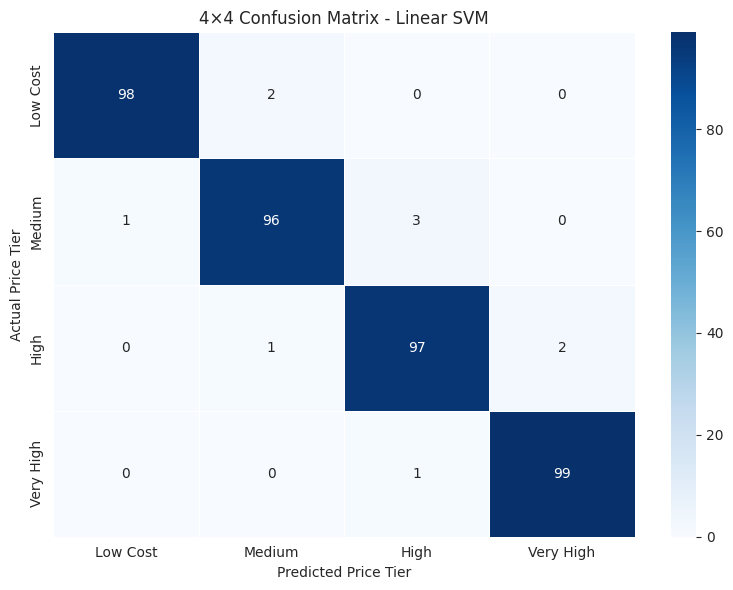


Per-Class Accuracy:
0 - Low Cost: 0.9800
1 - Medium: 0.9600
2 - High: 0.9700
3 - Very High: 0.9900


In [ ]:
# ============================================================
# CONFUSION MATRIX
# ============================================================

# Identify best model
best_model_name = results_df.loc[
    0,
    "Model"
]

best_predictions = predictions[
    best_model_name
]

print("Best Performing Model:")
print(best_model_name)

# Generate confusion matrix
cm = confusion_matrix(
    y_test,
    best_predictions
)

print("\nConfusion Matrix:")
print(cm)

# Heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.5,
    xticklabels=[
        "Low Cost",
        "Medium",
        "High",
        "Very High"
    ],
    yticklabels=[
        "Low Cost",
        "Medium",
        "High",
        "Very High"
    ]
)

plt.title(
    f"4×4 Confusion Matrix - {best_model_name}"
)

plt.xlabel("Predicted Price Tier")
plt.ylabel("Actual Price Tier")

plt.tight_layout()
plt.show()

# Per-class accuracy
class_accuracy = (
    cm.diagonal() /
    cm.sum(axis=1)
)

print("\nPer-Class Accuracy:")

for i, accuracy in enumerate(class_accuracy):
    print(
        f"{i} - "
        f"{['Low Cost', 'Medium', 'High', 'Very High'][i]}: "
        f"{accuracy:.4f}"
    )


Decision Tree Feature Importance:


,Importance
ram,0.665397
battery_power,0.123354
px_height,0.084130
px_width,0.082684
mobile_wt,0.013721
int_memory,0.010709
talk_time,0.009926
sc_w,0.001877
pc,0.001836
clock_speed,0.001390


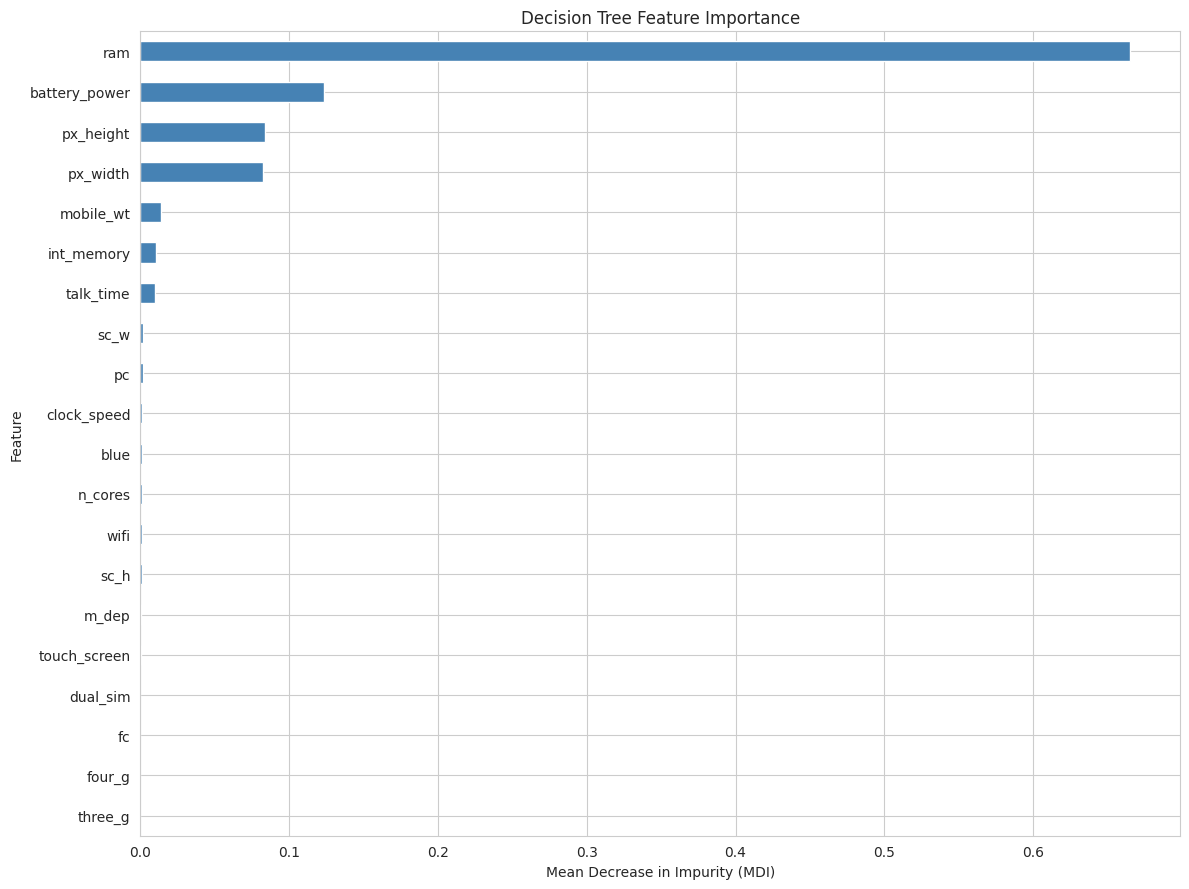


Top 10 Most Important Features:


,Importance
ram,0.665397
battery_power,0.123354
px_height,0.084130
px_width,0.082684
mobile_wt,0.013721
int_memory,0.010709
talk_time,0.009926
sc_w,0.001877
pc,0.001836
clock_speed,0.001390


In [ ]:
# ============================================================
# DECISION TREE FEATURE IMPORTANCE
# ============================================================

feature_importance = pd.Series(
    best_dt.feature_importances_,
    index=X.columns
).sort_values(
    ascending=False
)

print("Decision Tree Feature Importance:")
display(
    feature_importance.to_frame(
        "Importance"
    )
)

# Plot all features
plt.figure(figsize=(12, 9))

feature_importance.sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.title(
    "Decision Tree Feature Importance"
)

plt.xlabel(
    "Mean Decrease in Impurity (MDI)"
)

plt.ylabel("Feature")

plt.tight_layout()
plt.show()

# Top 10 features
print("\nTop 10 Most Important Features:")

display(
    feature_importance
    .head(10)
    .to_frame("Importance")
)


Decision Tree Feature Importance:


,Importance
ram,0.665397
battery_power,0.123354
px_height,0.084130
px_width,0.082684
mobile_wt,0.013721
int_memory,0.010709
talk_time,0.009926
sc_w,0.001877
pc,0.001836
clock_speed,0.001390


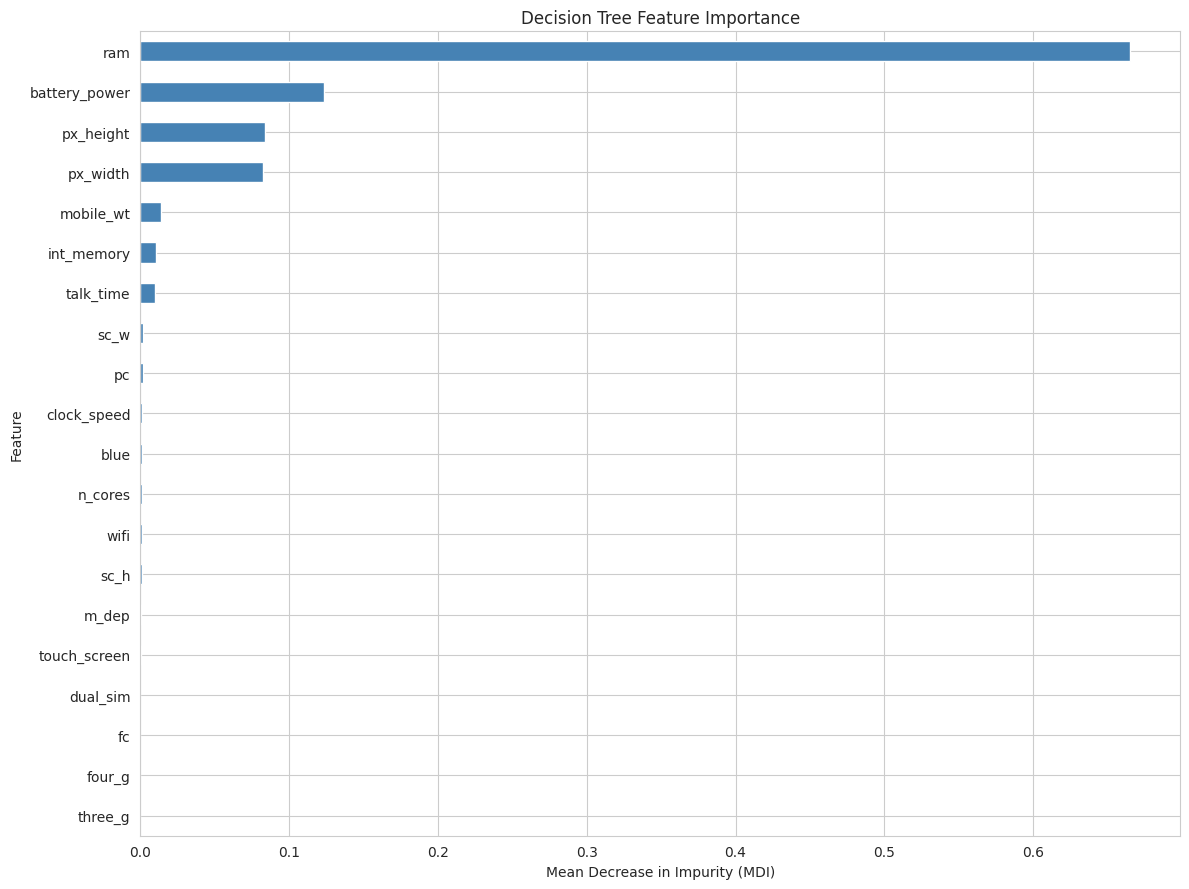


Top 10 Most Important Features:


,Importance
ram,0.665397
battery_power,0.123354
px_height,0.084130
px_width,0.082684
mobile_wt,0.013721
int_memory,0.010709
talk_time,0.009926
sc_w,0.001877
pc,0.001836
clock_speed,0.001390


In [ ]:
# ============================================================
# DECISION TREE FEATURE IMPORTANCE
# ============================================================

feature_importance = pd.Series(
    best_dt.feature_importances_,
    index=X.columns
).sort_values(
    ascending=False
)

print("Decision Tree Feature Importance:")
display(
    feature_importance.to_frame(
        "Importance"
    )
)

# Plot all features
plt.figure(figsize=(12, 9))

feature_importance.sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.title(
    "Decision Tree Feature Importance"
)

plt.xlabel(
    "Mean Decrease in Impurity (MDI)"
)

plt.ylabel("Feature")

plt.tight_layout()
plt.show()

# Top 10 features
print("\nTop 10 Most Important Features:")

display(
    feature_importance
    .head(10)
    .to_frame("Importance")
)


Permutation Importance:


,Feature,Importance Mean,Importance Std
0,ram,0.59825,0.014708
1,battery_power,0.15500,0.024469
2,px_width,0.07000,0.011402
3,px_height,0.05650,0.008307
4,mobile_wt,0.00825,0.004479
5,clock_speed,0.00600,0.002784
6,wifi,0.00175,0.001146
7,sc_w,0.00025,0.002358
8,dual_sim,0.00000,0.000000
9,blue,0.00000,0.000000


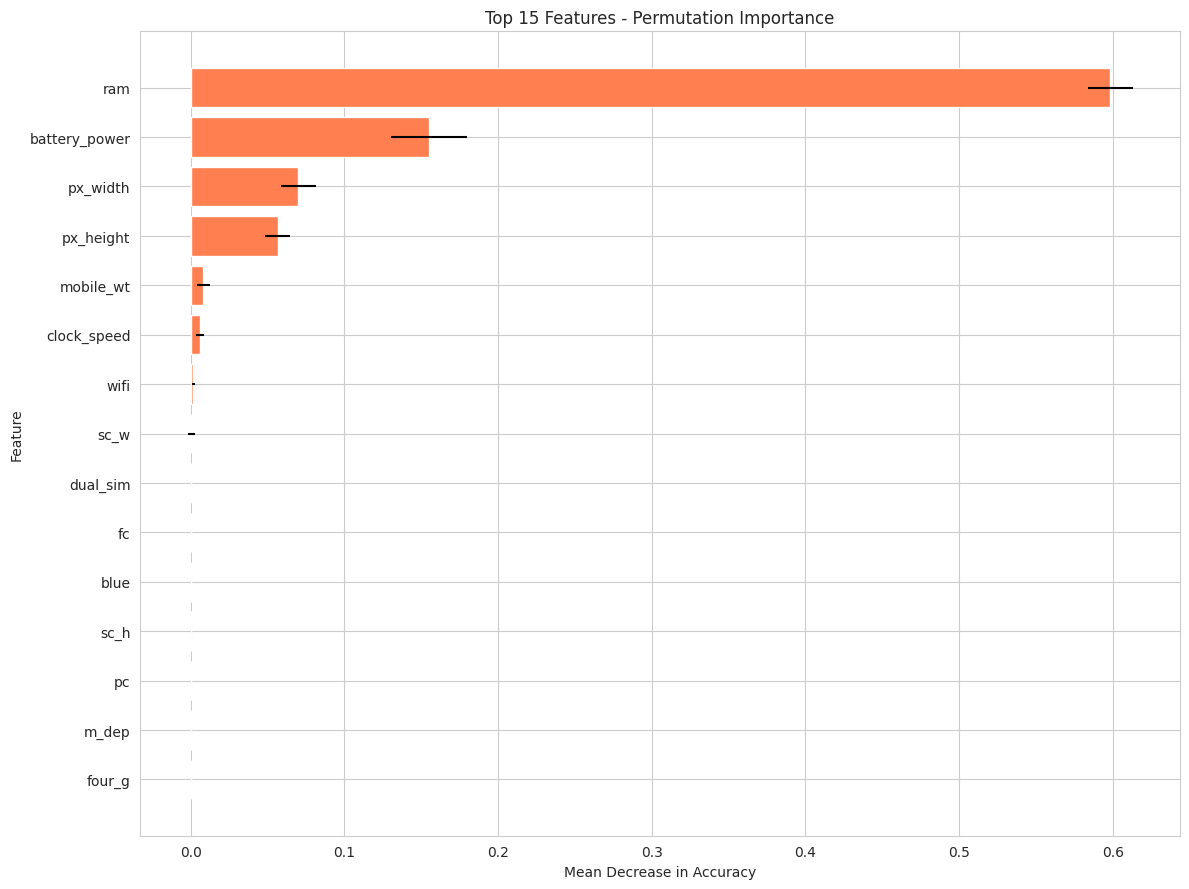

In [ ]:
# ============================================================
# PERMUTATION IMPORTANCE
# ============================================================

# Calculate permutation importance
perm_result = permutation_importance(
    best_dt,
    X_test,
    y_test,
    n_repeats=10,
    random_state=RANDOM_STATE,
    scoring="accuracy"
)

permutation_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance Mean": perm_result.importances_mean,
    "Importance Std": perm_result.importances_std
})

permutation_df = permutation_df.sort_values(
    "Importance Mean",
    ascending=False
).reset_index(drop=True)

print("Permutation Importance:")
display(permutation_df)

# Plot
plt.figure(figsize=(12, 9))

top_perm = (
    permutation_df
    .head(15)
    .sort_values("Importance Mean")
)

plt.barh(
    top_perm["Feature"],
    top_perm["Importance Mean"],
    xerr=top_perm["Importance Std"],
    color="coral"
)

plt.title(
    "Top 15 Features - Permutation Importance"
)

plt.xlabel(
    "Mean Decrease in Accuracy"
)

plt.ylabel("Feature")

plt.tight_layout()
plt.show()


FINAL MODEL COMPARISON:


,Model,CV Accuracy,Accuracy,Precision,Recall,F1 Score
0,Linear SVM,0.9638,0.9750,0.9750,0.9750,0.9750
1,RBF SVM,0.9363,0.9675,0.9676,0.9675,0.9675
2,Decision Tree,0.8375,0.8600,0.8615,0.8600,0.8597
3,Gaussian Naive Bayes,0.8037,0.8100,0.8113,0.8100,0.8105
4,KNN,0.6069,0.6425,0.6399,0.6425,0.6408


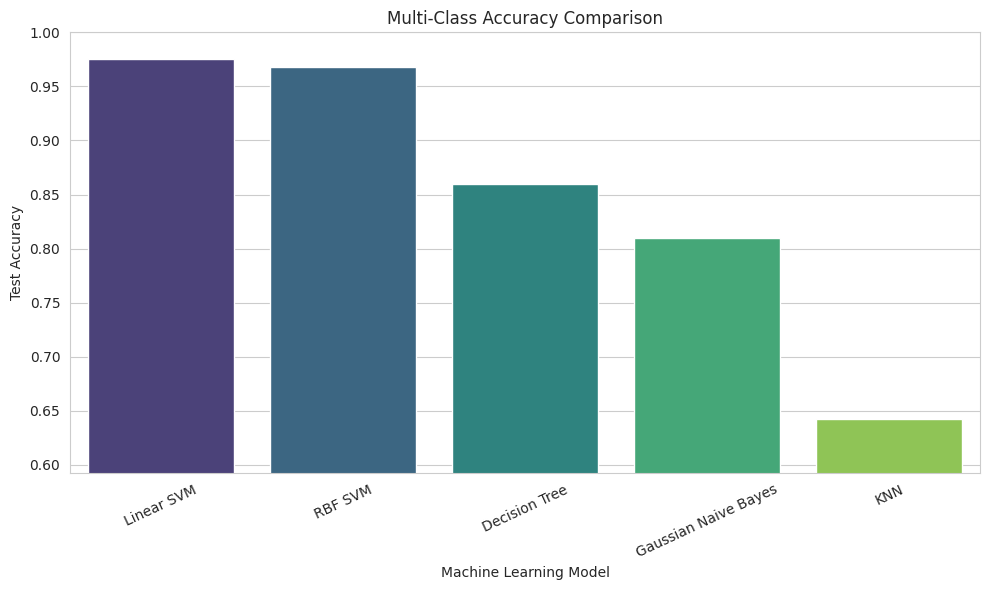

In [ ]:
# ============================================================
# MODEL COMPARISON
# ============================================================

# Add CV scores
cv_scores = {
    "Decision Tree": dt_grid.best_score_,
    "Gaussian Naive Bayes": cross_val_score(
        GaussianNB(),
        X_train_scaled,
        y_train,
        cv=cv_strategy,
        scoring="accuracy",
        n_jobs=-1
    ).mean(),
    "Linear SVM": linear_svm_grid.best_score_,
    "RBF SVM": rbf_svm_grid.best_score_,
    "KNN": knn_grid.best_score_
}

results_df["CV Accuracy"] = (
    results_df["Model"]
    .map(cv_scores)
)

# Rearrange columns
results_df = results_df[
    [
        "Model",
        "CV Accuracy",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ]
]

print("FINAL MODEL COMPARISON:")
display(
    results_df.style.format({
        "CV Accuracy": "{:.4f}",
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}"
    })
)

# Accuracy comparison plot
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy",
    hue="Model",
    palette="viridis",
    legend=False
)

plt.title(
    "Multi-Class Accuracy Comparison"
)

plt.xlabel("Machine Learning Model")
plt.ylabel("Test Accuracy")

plt.ylim(
    max(0, results_df["Accuracy"].min() - 0.05),
    1.0
)

plt.xticks(rotation=25)

plt.tight_layout()
plt.show()


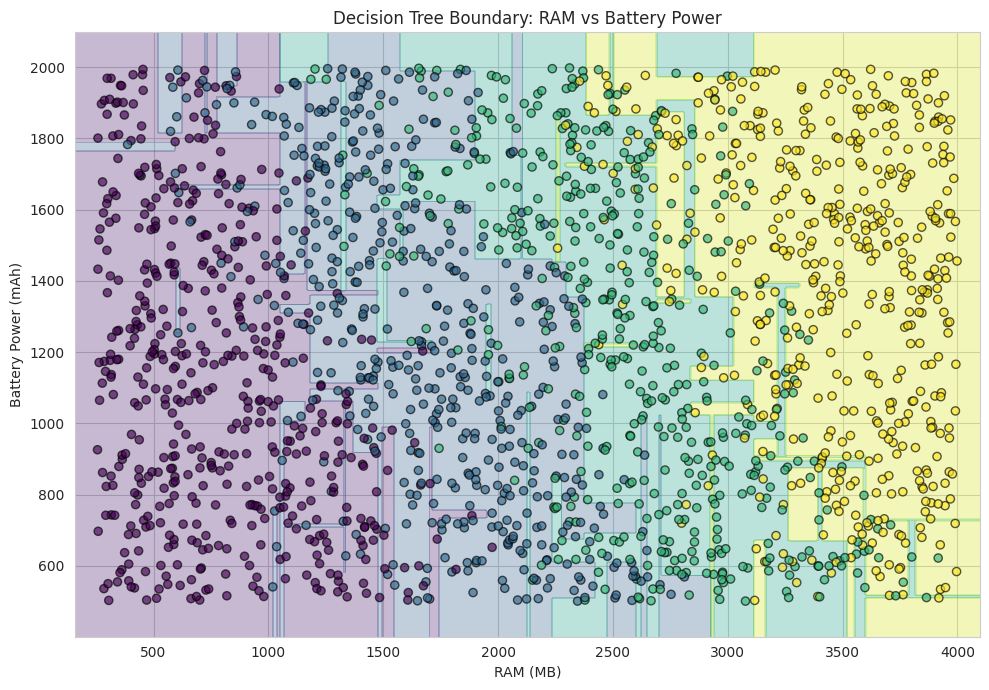

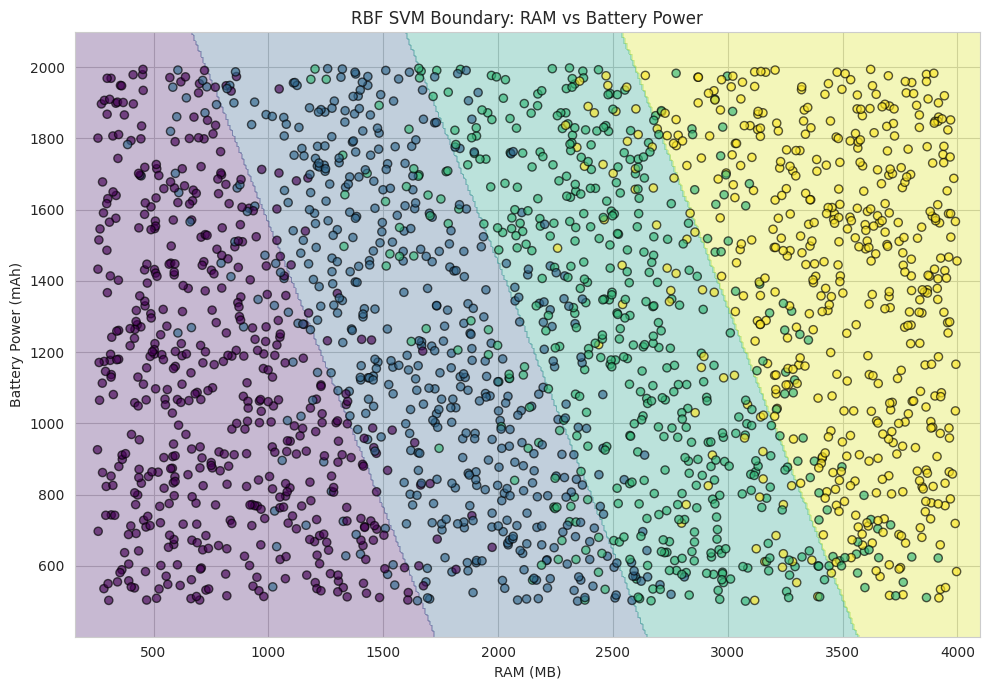

In [ ]:
# ============================================================
# DECISION BOUNDARIES
# RAM VS BATTERY POWER
# ============================================================

# Select two features
X_2d = df[
    ["ram", "battery_power"]
]

y_2d = df[
    "price_range"
]

# Split 2D dataset
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X_2d,
    y_2d,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_2d
)

# Scale for SVM
scaler_2d = StandardScaler()

X2_train_scaled = scaler_2d.fit_transform(
    X2_train
)

X2_test_scaled = scaler_2d.transform(
    X2_test
)

# ------------------------------------------------------------
# 2D DECISION TREE
# ------------------------------------------------------------

dt_2d = DecisionTreeClassifier(
    max_depth=best_dt.get_params()["max_depth"],
    random_state=RANDOM_STATE
)

dt_2d.fit(
    X2_train,
    y2_train
)

# ------------------------------------------------------------
# 2D RBF SVM
# ------------------------------------------------------------

svm_2d = SVC(
    kernel="rbf",
    C=best_rbf_svm.get_params()["C"],
    gamma=best_rbf_svm.get_params()["gamma"]
)

svm_2d.fit(
    X2_train_scaled,
    y2_train
)

# ------------------------------------------------------------
# FUNCTION FOR DECISION BOUNDARY
# ------------------------------------------------------------

def plot_boundary(
    model,
    X_data,
    y_data,
    title,
    scaled=False,
    scaler=None
):

    X_array = X_data.values

    # Create mesh range
    x_min = X_array[:, 0].min() - 100
    x_max = X_array[:, 0].max() + 100

    y_min = X_array[:, 1].min() - 100
    y_max = X_array[:, 1].max() + 100

    xx, yy = np.meshgrid(
        np.linspace(
            x_min,
            x_max,
            400
        ),
        np.linspace(
            y_min,
            y_max,
            400
        )
    )

    grid = np.c_[
        xx.ravel(),
        yy.ravel()
    ]

    if scaled:
        grid_for_model = scaler.transform(grid)
    else:
        grid_for_model = grid

    predictions_grid = model.predict(
        grid_for_model
    )

    predictions_grid = predictions_grid.reshape(
        xx.shape
    )

    plt.figure(figsize=(10, 7))

    plt.contourf(
        xx,
        yy,
        predictions_grid,
        alpha=0.30,
        cmap="viridis"
    )

    plt.scatter(
        X_array[:, 0],
        X_array[:, 1],
        c=y_data,
        cmap="viridis",
        edgecolor="black",
        alpha=0.65,
        s=35
    )

    plt.xlabel("RAM (MB)")
    plt.ylabel("Battery Power (mAh)")
    plt.title(title)

    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# DECISION TREE BOUNDARY
# ------------------------------------------------------------

plot_boundary(
    dt_2d,
    X_2d,
    y_2d,
    "Decision Tree Boundary: RAM vs Battery Power"
)

# ------------------------------------------------------------
# RBF SVM BOUNDARY
# ------------------------------------------------------------

plot_boundary(
    svm_2d,
    X_2d,
    y_2d,
    "RBF SVM Boundary: RAM vs Battery Power",
    scaled=True,
    scaler=scaler_2d
)


Best Model:
Linear SVM

Total Test Samples:
400

Correct Predictions:
390

Incorrect Predictions:
10

Error Rate: 0.025

Misclassified Examples:


,ram,battery_power,px_height,px_width,int_memory,clock_speed,Actual,Predicted,Ordinal Error
1341,2253,1423,501,640,44,0.6,1,2,1
751,1026,1331,1109,1226,16,1.6,1,0,1
1968,635,1667,1211,1396,21,1.0,0,1,1
55,2552,1936,667,1036,46,2.1,2,3,1
1176,2836,1590,1058,1109,14,1.5,3,2,1
980,934,1597,64,1667,34,2.3,0,1,1
1164,2832,860,1573,1581,40,1.3,2,3,1
127,1496,1564,1259,1965,25,2.3,1,2,1
1805,2466,534,911,1220,2,0.5,2,1,1
724,2630,696,649,907,51,0.5,1,2,1



Ordinal Error Distribution:


,count
Ordinal Error,
0,390
1,10


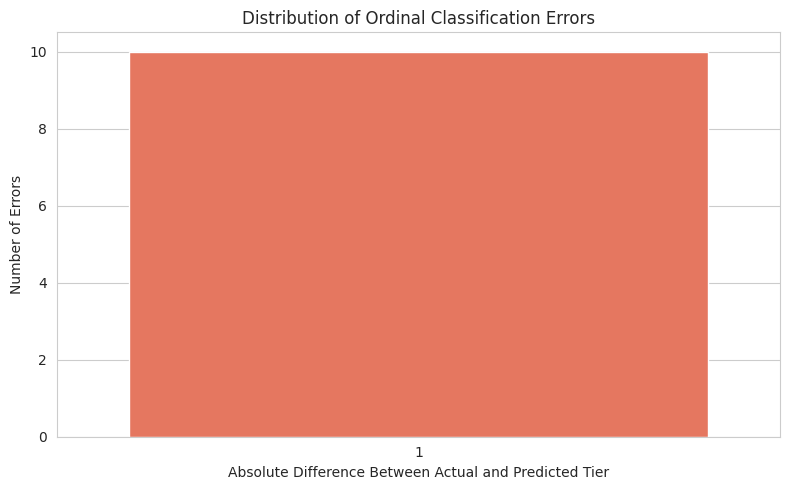

In [ ]:
# ============================================================
# ERROR ANALYSIS
# ============================================================

# Create error-analysis DataFrame
error_analysis = X_test.copy()

error_analysis["Actual"] = y_test

error_analysis["Predicted"] = best_predictions

error_analysis["Correct"] = (
    error_analysis["Actual"] ==
    error_analysis["Predicted"]
)

# Ordinal error
error_analysis["Ordinal Error"] = (
    abs(
        error_analysis["Actual"] -
        error_analysis["Predicted"]
    )
)

# Misclassified records
errors_only = error_analysis[
    error_analysis["Correct"] == False
].copy()

print("Best Model:")
print(best_model_name)

print("\nTotal Test Samples:")
print(len(error_analysis))

print("\nCorrect Predictions:")
print(error_analysis["Correct"].sum())

print("\nIncorrect Predictions:")
print((~error_analysis["Correct"]).sum())

print(
    "\nError Rate:",
    round(
        (~error_analysis["Correct"]).mean(),
        4
    )
)

print("\nMisclassified Examples:")
display(
    errors_only[
        [
            "ram",
            "battery_power",
            "px_height",
            "px_width",
            "int_memory",
            "clock_speed",
            "Actual",
            "Predicted",
            "Ordinal Error"
        ]
    ].head(20)
)

# Ordinal error distribution
print("\nOrdinal Error Distribution:")
display(
    error_analysis[
        "Ordinal Error"
    ].value_counts().sort_index()
)

# Error type visualization
plt.figure(figsize=(8, 5))

sns.countplot(
    data=errors_only,
    x="Ordinal Error",
    hue="Ordinal Error",
    palette="Reds",
    legend=False
)

plt.title(
    "Distribution of Ordinal Classification Errors"
)

plt.xlabel(
    "Absolute Difference Between Actual and Predicted Tier"
)

plt.ylabel("Number of Errors")

plt.tight_layout()
plt.show()


In [ ]:
# ============================================================
# FINAL CONCLUSIONS
# ============================================================

# Identify best model
best_row = results_df.iloc[0]

print("=" * 75)
print("FINAL PROJECT CONCLUSION")
print("=" * 75)

print("\nBest Performing Model:")
print(best_row["Model"])

print(
    f"\nTest Accuracy: "
    f"{best_row['Accuracy']:.4f}"
)

print(
    f"Test Precision: "
    f"{best_row['Precision']:.4f}"
)

print(
    f"Test Recall: "
    f"{best_row['Recall']:.4f}"
)

print(
    f"Test F1 Score: "
    f"{best_row['F1 Score']:.4f}"
)

# Top feature
top_feature = feature_importance.index[0]
top_importance = feature_importance.iloc[0]

print("\nMost Important Decision Tree Feature:")
print(
    f"{top_feature} "
    f"(importance = {top_importance:.4f})"
)

# Permutation top feature
top_perm_feature = permutation_df.iloc[0]["Feature"]
top_perm_value = permutation_df.iloc[0]["Importance Mean"]

print("\nMost Important Permutation Feature:")
print(
    f"{top_perm_feature} "
    f"(importance = {top_perm_value:.4f})"
)

print("\nKey Findings:")
print(
    "1. Smartphone hardware specifications can be used "
    "to classify devices into four price tiers."
)

print(
    "2. Multiple machine-learning algorithms were compared "
    "using a consistent train-test methodology."
)

print(
    "3. Hyperparameter optimization was performed using "
    "five-fold stratified cross-validation."
)

print(
    "4. Feature importance and permutation importance were "
    "used to investigate hardware influence."
)

print(
    "5. RAM was specifically investigated as a major "
    "predictor of smartphone price tier."
)

print(
    "6. Confusion matrices and ordinal errors were used "
    "to understand model mistakes."
)

print(
    "7. Decision boundaries using RAM and battery power "
    "illustrated differences between tree and nonlinear SVM models."
)

print(
    "\nOverall, the selected machine-learning approach can "
    "support smartphone market segmentation and product "
    "pricing-strategy analysis."
)

print("\n" + "=" * 75)
print("PROJECT 59 COMPLETED")
print("=" * 75)


FINAL PROJECT CONCLUSION

Best Performing Model:
Linear SVM

Test Accuracy: 0.9750
Test Precision: 0.9750
Test Recall: 0.9750
Test F1 Score: 0.9750

Most Important Decision Tree Feature:
ram (importance = 0.6654)

Most Important Permutation Feature:
ram (importance = 0.5982)

Key Findings:
1. Smartphone hardware specifications can be used to classify devices into four price tiers.
2. Multiple machine-learning algorithms were compared using a consistent train-test methodology.
3. Hyperparameter optimization was performed using five-fold stratified cross-validation.
4. Feature importance and permutation importance were used to investigate hardware influence.
5. RAM was specifically investigated as a major predictor of smartphone price tier.
6. Confusion matrices and ordinal errors were used to understand model mistakes.
7. Decision boundaries using RAM and battery power illustrated differences between tree and nonlinear SVM models.

Overall, the selected machine-learning approach can sup